# Phase 9 — Baseline Models

**Objective:** Train and evaluate four baseline classifiers using full end-to-end Scikit-Learn Pipelines
(DomainFeatureEngineer → ColumnTransformer → Estimator) with 5-fold cross-validation.

| Model | Imbalance Strategy | Notes |
|---|---|---|
| `DummyClassifier` | N/A | Stratified random — performance floor |
| `LogisticRegression` | `class_weight='balanced'` | Linear baseline, needs scaling |
| `RandomForestClassifier` | `class_weight='balanced'` | Tree ensemble, no scaling needed |
| `XGBClassifier` | `scale_pos_weight=neg/pos` | Gradient boost, recomputed per fold |

**Rules enforced:**
- ✅ No leakage: pipeline fitted per fold on training split only
- ✅ `test.csv` untouched
- ✅ `random_state=42` everywhere
- ✅ Imbalance handled via `class_weight` / `scale_pos_weight`

## 9.0  Setup & Imports

In [1]:
import sys, json, time, warnings, pathlib
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
warnings.filterwarnings('ignore')

# Find project root (works when kernel cwd is notebooks/ or project root)
def _find_root(start):
    for p in [start] + list(start.parents):
        if (p / 'params.yaml').exists():
            return p
    return start

import os
PROJECT_ROOT = _find_root(pathlib.Path.cwd())
os.chdir(PROJECT_ROOT)
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, f1_score, precision_score, recall_score,
    roc_auc_score, roc_curve, precision_recall_curve,
    average_precision_score, confusion_matrix, ConfusionMatrixDisplay
)
from xgboost import XGBClassifier

from src.data.preprocessing import build_full_pipeline
from src.utils.config import PARAMS

RANDOM_STATE = PARAMS['random_state']
TARGET       = PARAMS['dataset']['target_column']
print(f'Project root : {PROJECT_ROOT}')
print(f'Random state : {RANDOM_STATE}')
print(f'Target column: {TARGET}')

Project root : C:\Users\Abhishek\OneDrive\Pictures\Desktop\ChurnOps
Random state : 42
Target column: Churn


## 9.1  Load Training Data & CV Folds

In [2]:
df_train = pd.read_csv('data/processed/train.csv')
with open('data/processed/cv_folds.json') as f:
    cv_folds = json.load(f)

print(f'Training set : {df_train.shape[0]:,} rows x {df_train.shape[1]} columns')
print(f'CV folds     : {len(cv_folds)}')

X = df_train.drop(columns=[TARGET])
y = df_train[TARGET]

pos_count   = int((y == 1).sum())
neg_count   = int((y == 0).sum())
class_ratio = neg_count / pos_count
print(f'Positives (Churn=1) : {pos_count:,}  ({pos_count/len(y)*100:.1f}%)')
print(f'Negatives (Churn=0) : {neg_count:,}  ({neg_count/len(y)*100:.1f}%)')
print(f'neg/pos ratio       : {class_ratio:.4f}  -> XGBoost scale_pos_weight')

Training set : 5,634 rows x 20 columns
CV folds     : 5
Positives (Churn=1) : 1,495  (26.5%)
Negatives (Churn=0) : 4,139  (73.5%)
neg/pos ratio       : 2.7686  -> XGBoost scale_pos_weight


## 9.2  Verify CV Fold Class Balance

In [3]:
# cv_folds is a dict: {'fold_1': {'train_indices': [...], 'val_indices': [...]}, ...}
FOLD_NAMES = sorted(cv_folds.keys())
fold_stats = []
for i, fold_name in enumerate(FOLD_NAMES):
    fold  = cv_folds[fold_name]
    y_tr  = y.iloc[fold['train_indices']]
    y_val = y.iloc[fold['val_indices']]
    fold_stats.append({
        'Fold'        : i + 1,
        'Train n'     : len(y_tr),
        'Val n'       : len(y_val),
        'Train churn%': round(y_tr.mean() * 100, 2),
        'Val churn%'  : round(y_val.mean() * 100, 2),
    })

pd.DataFrame(fold_stats)

,Fold,Train n,Val n,Train churn%,Val churn%
0,1,4507,1127,26.54,26.53
1,2,4507,1127,26.54,26.53
2,3,4507,1127,26.54,26.53
3,4,4507,1127,26.54,26.53
4,5,4508,1126,26.53,26.55


## 9.3  Build Baseline Pipelines

> Each model is a `Pipeline(DomainFeatureEngineer -> ColumnTransformer -> Estimator)`.  
> Fresh instances are built **per fold** so no fitted state leaks between folds.

In [4]:
def _compute_spw(y_series):
    neg = (y_series == 0).sum()
    pos = (y_series == 1).sum()
    return float(neg / pos) if pos > 0 else 1.0

def build_pipelines(y_ref):
    spw = _compute_spw(y_ref)
    return {
        'DummyClassifier': build_full_pipeline(
            estimator=DummyClassifier(strategy='stratified', random_state=RANDOM_STATE),
            scale_numeric=True,
        ),
        'LogisticRegression': build_full_pipeline(
            estimator=LogisticRegression(
                class_weight='balanced', max_iter=1000,
                solver='lbfgs', random_state=RANDOM_STATE,
            ),
            scale_numeric=True,
        ),
        'RandomForest': build_full_pipeline(
            estimator=RandomForestClassifier(
                n_estimators=200, class_weight='balanced',
                random_state=RANDOM_STATE, n_jobs=-1,
            ),
            scale_numeric=False,
        ),
        'XGBoost': build_full_pipeline(
            estimator=XGBClassifier(
                n_estimators=200, scale_pos_weight=spw,
                eval_metric='logloss', random_state=RANDOM_STATE,
                n_jobs=-1, verbosity=0,
            ),
            scale_numeric=False,
        ),
    }

# Preview pipeline steps
sample_pipes = build_pipelines(y)
print('Pipelines created:')
for name, pipe in sample_pipes.items():
    print(f'  {name:<24} steps={list(pipe.named_steps.keys())}')

Pipelines created:
  DummyClassifier          steps=['feature_engineer', 'preprocessor', 'model']
  LogisticRegression       steps=['feature_engineer', 'preprocessor', 'model']
  RandomForest             steps=['feature_engineer', 'preprocessor', 'model']
  XGBoost                  steps=['feature_engineer', 'preprocessor', 'model']


## 9.4  Run 5-Fold Cross-Validation

> Rule R3: Each fold builds **fresh** unfitted pipelines and fits them on the training split of that fold only. No data from the validation split is ever used for fitting.

In [5]:
MODEL_NAMES = ['DummyClassifier', 'LogisticRegression', 'RandomForest', 'XGBoost']

# cv_folds is a dict: {'fold_1': {'train_indices': [...], 'val_indices': [...]}, ...}
FOLD_NAMES = sorted(cv_folds.keys())

def evaluate_fold(pipe, X_tr, y_tr, X_val, y_val):
    pipe.fit(X_tr, y_tr)
    y_pred = pipe.predict(X_val)
    try:
        y_prob = pipe.predict_proba(X_val)[:, 1]
    except AttributeError:
        y_prob = pipe.decision_function(X_val)
    return {
        'accuracy' : round(accuracy_score(y_val, y_pred), 4),
        'precision': round(precision_score(y_val, y_pred, zero_division=0), 4),
        'recall'   : round(recall_score(y_val, y_pred, zero_division=0), 4),
        'f1'       : round(f1_score(y_val, y_pred, zero_division=0), 4),
        'roc_auc'  : round(roc_auc_score(y_val, y_prob), 4),
        'y_prob'   : y_prob,
        'y_pred'   : y_pred,
        'y_true'   : y_val.values,
    }

fold_results = {name: [] for name in MODEL_NAMES}
t_total = time.perf_counter()

for fold_idx, fold_name in enumerate(FOLD_NAMES):
    fold  = cv_folds[fold_name]
    X_tr  = X.iloc[fold['train_indices']].reset_index(drop=True)
    y_tr  = y.iloc[fold['train_indices']].reset_index(drop=True)
    X_val = X.iloc[fold['val_indices']].reset_index(drop=True)
    y_val = y.iloc[fold['val_indices']].reset_index(drop=True)

    pipes = build_pipelines(y_tr)  # fresh instances per fold

    print(f"\n{'='*65}")
    print(f" Fold {fold_idx+1}/{len(FOLD_NAMES)} | train={len(y_tr)}  val={len(y_val)}  "
          f"pos_rate_train={y_tr.mean():.3f}  pos_rate_val={y_val.mean():.3f}")
    print(f"{'='*65}")

    for name in MODEL_NAMES:
        pipe = pipes[name]
        if name == 'XGBoost':
            pipe.named_steps['model'].set_params(scale_pos_weight=_compute_spw(y_tr))
        t0 = time.perf_counter()
        metrics = evaluate_fold(pipe, X_tr, y_tr, X_val, y_val)
        elapsed = time.perf_counter() - t0
        metrics['train_time_s'] = round(elapsed, 2)
        fold_results[name].append(metrics)
        print(f"  {name:<24} F1={metrics['f1']:.4f}  AUC={metrics['roc_auc']:.4f}  "
              f"Recall={metrics['recall']:.4f}  [{elapsed:.1f}s]")

print(f"\nTotal CV time: {time.perf_counter()-t_total:.1f}s")


 Fold 1/5 | train=4507  val=1127  pos_rate_train=0.265  pos_rate_val=0.265
  DummyClassifier          F1=0.3128  AUC=0.5316  Recall=0.3144  [0.1s]


  LogisticRegression       F1=0.6447  AUC=0.8462  Recall=0.8194  [0.1s]


  RandomForest             F1=0.5369  AUC=0.8180  Recall=0.4749  [0.4s]


  XGBoost                  F1=0.5801  AUC=0.8154  Recall=0.6054  [0.2s]

 Fold 2/5 | train=4507  val=1127  pos_rate_train=0.265  pos_rate_val=0.265
  DummyClassifier          F1=0.2862  AUC=0.5134  Recall=0.2876  [0.1s]
  LogisticRegression       F1=0.5840  AUC=0.8255  Recall=0.7324  [0.1s]


  RandomForest             F1=0.5269  AUC=0.8067  Recall=0.4582  [0.4s]


...

  RandomForest             F1=0.5295  AUC=0.8135  Recall=0.4649  [0.5s]


  XGBoost                  F1=0.5952  AUC=0.8250  Recall=0.6221  [0.3s]

 Fold 5/5 | train=4508  val=1126  pos_rate_train=0.265  pos_rate_val=0.266
  DummyClassifier          F1=0.2596  AUC=0.4950  Recall=0.2609  [0.1s]


  LogisticRegression       F1=0.6387  AUC=0.8561  Recall=0.7893  [0.1s]


  RandomForest             F1=0.5703  AUC=0.8414  Recall=0.4883  [0.5s]


  XGBoost                  F1=0.5672  AUC=0.8172  Recall=0.5786  [0.3s]

Total CV time: 4.6s


## 9.5  Summary Table — Mean ± Std Across Folds

In [6]:
METRIC_COLS = ['accuracy', 'precision', 'recall', 'f1', 'roc_auc']

rows = []
for name in MODEL_NAMES:
    folds_data = fold_results[name]
    row = {'Model': name}
    for m in METRIC_COLS:
        vals = [fd[m] for fd in folds_data]
        row[m] = f"{np.mean(vals):.4f} ± {np.std(vals):.4f}"
    row['mean_train_s'] = f"{np.mean([fd['train_time_s'] for fd in folds_data]):.1f}"
    rows.append(row)

df_summary = pd.DataFrame(rows).set_index('Model')
display(df_summary)

min_f1  = PARAMS['registry']['min_f1']
min_auc = PARAMS['registry']['min_roc_auc']
min_rec = PARAMS['registry']['min_recall']
print(f'\n[!] Registry gates: F1>={min_f1}  ROC-AUC>={min_auc}  Recall>={min_rec}')

,accuracy,precision,recall,f1,roc_auc,mean_train_s
Model,,,,,,
DummyClassifier,0.6139 ± 0.0133,0.2749 ± 0.0248,0.2776 ± 0.0250,0.2762 ± 0.0249,0.5065 ± 0.0171,0.1
LogisticRegression,0.7482 ± 0.0156,0.5165 ± 0.0194,0.7946 ± 0.0429,0.6258 ± 0.0257,0.8460 ± 0.0125,0.1
RandomForest,0.7898 ± 0.0101,0.6400 ± 0.0286,0.4769 ± 0.0147,0.5465 ± 0.0191,0.8216 ± 0.0121,0.5
XGBoost,0.7678 ± 0.0095,0.5582 ± 0.0165,0.5994 ± 0.0221,0.5780 ± 0.0186,0.8150 ± 0.0072,0.3



[!] Registry gates: F1>=0.6  ROC-AUC>=0.75  Recall>=0.6


## 9.6  Visualisations
### 9.6.1  F1 / ROC-AUC Boxplots Across Folds

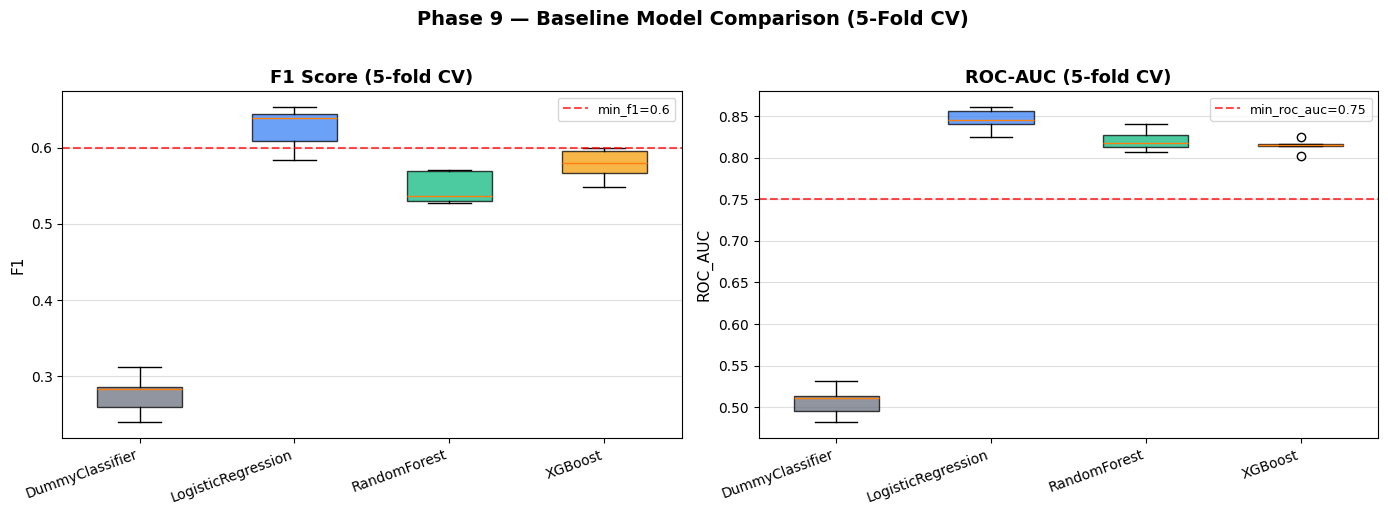

Saved: reports/baseline_fold_comparison.png


In [7]:
COLORS = ['#6B7280', '#3B82F6', '#10B981', '#F59E0B']

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, metric, title in zip(
    axes, ['f1', 'roc_auc'],
    ['F1 Score (5-fold CV)', 'ROC-AUC (5-fold CV)'],
):
    data_plot = [[fd[metric] for fd in fold_results[n]] for n in MODEL_NAMES]
    bp = ax.boxplot(data_plot, patch_artist=True, widths=0.55)
    for patch, c in zip(bp['boxes'], COLORS):
        patch.set_facecolor(c); patch.set_alpha(0.75)
    ax.set_xticks(range(1, len(MODEL_NAMES)+1))
    ax.set_xticklabels(MODEL_NAMES, rotation=20, ha='right', fontsize=10)
    ax.set_title(title, fontsize=13, fontweight='bold')
    ax.set_ylabel(metric.upper(), fontsize=11)
    ax.grid(axis='y', alpha=0.4)
    thresh_val = PARAMS['registry']['min_f1'] if metric=='f1' else PARAMS['registry']['min_roc_auc']
    ax.axhline(thresh_val, color='red', ls='--', alpha=0.7,
               label=f'min_{metric}={thresh_val}')
    ax.legend(fontsize=9)

plt.suptitle('Phase 9 — Baseline Model Comparison (5-Fold CV)',
             fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('reports/baseline_fold_comparison.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved: reports/baseline_fold_comparison.png')

### 9.6.2  ROC Curves (Last Fold)

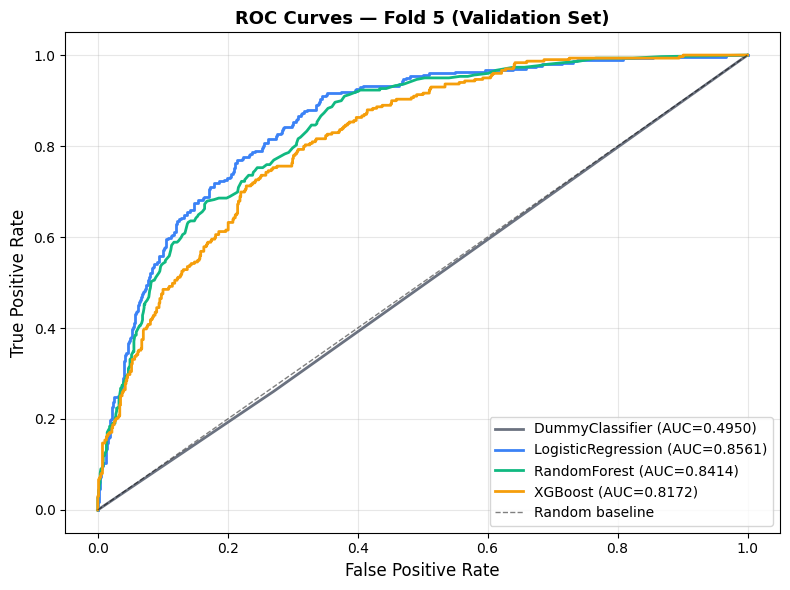

Saved: reports/baseline_roc_curves.png


In [8]:
fig, ax = plt.subplots(figsize=(8, 6))
for name, color in zip(MODEL_NAMES, COLORS):
    last = fold_results[name][-1]
    fpr, tpr, _ = roc_curve(last['y_true'], last['y_prob'])
    auc = roc_auc_score(last['y_true'], last['y_prob'])
    ax.plot(fpr, tpr, color=color, lw=2, label=f'{name} (AUC={auc:.4f})')
ax.plot([0,1],[0,1],'k--',lw=1,alpha=0.5,label='Random baseline')
ax.set_xlabel('False Positive Rate', fontsize=12)
ax.set_ylabel('True Positive Rate', fontsize=12)
ax.set_title('ROC Curves — Fold 5 (Validation Set)', fontsize=13, fontweight='bold')
ax.legend(loc='lower right', fontsize=10)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig('reports/baseline_roc_curves.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved: reports/baseline_roc_curves.png')

### 9.6.3  Precision-Recall Curves (Last Fold)

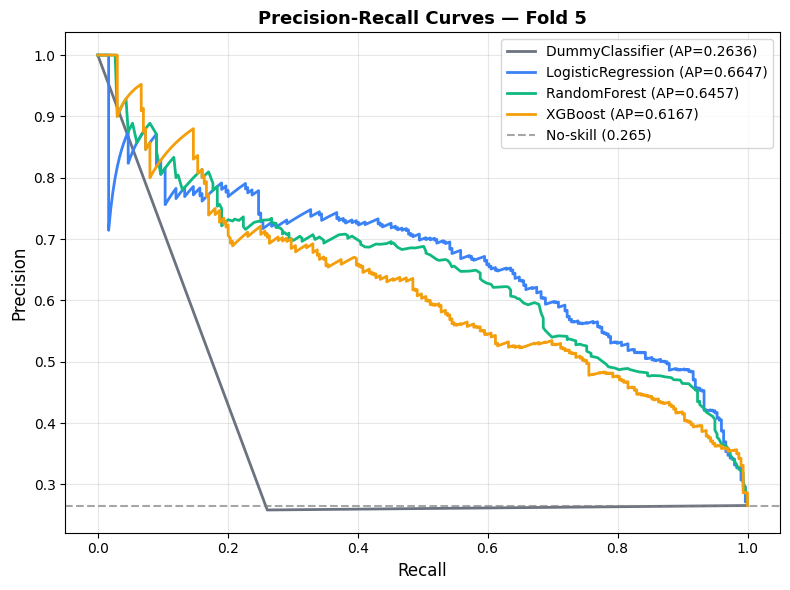

Saved: reports/baseline_pr_curves.png


In [9]:
fig, ax = plt.subplots(figsize=(8, 6))
for name, color in zip(MODEL_NAMES, COLORS):
    last = fold_results[name][-1]
    prec, rec, _ = precision_recall_curve(last['y_true'], last['y_prob'])
    ap = average_precision_score(last['y_true'], last['y_prob'])
    ax.plot(rec, prec, color=color, lw=2, label=f'{name} (AP={ap:.4f})')
ax.axhline(y.mean(), color='gray', ls='--', alpha=0.7,
           label=f'No-skill ({y.mean():.3f})')
ax.set_xlabel('Recall', fontsize=12)
ax.set_ylabel('Precision', fontsize=12)
ax.set_title('Precision-Recall Curves — Fold 5', fontsize=13, fontweight='bold')
ax.legend(loc='upper right', fontsize=10)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig('reports/baseline_pr_curves.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved: reports/baseline_pr_curves.png')

### 9.6.4  Confusion Matrices (Last Fold, All Models)

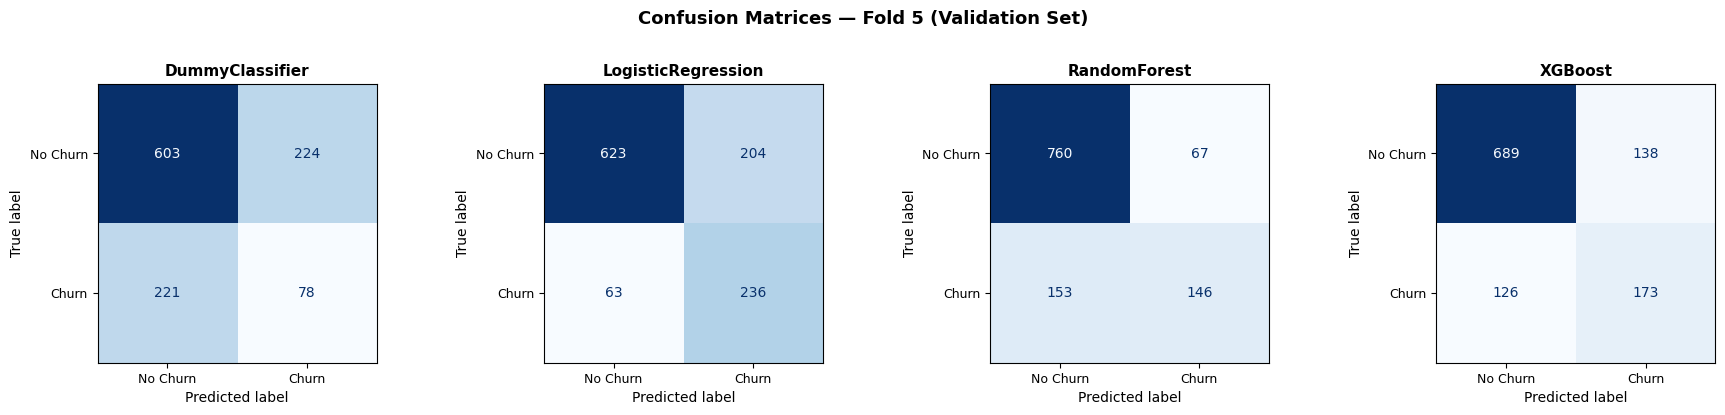

Saved: reports/baseline_confusion_matrices.png


In [10]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, name in zip(axes, MODEL_NAMES):
    last = fold_results[name][-1]
    cm = confusion_matrix(last['y_true'], last['y_pred'])
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['No Churn','Churn'])
    disp.plot(ax=ax, colorbar=False, cmap='Blues')
    ax.set_title(name, fontsize=11, fontweight='bold')
    ax.tick_params(labelsize=9)
plt.suptitle('Confusion Matrices — Fold 5 (Validation Set)',
             fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('reports/baseline_confusion_matrices.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved: reports/baseline_confusion_matrices.png')

## 9.7  Save Results to reports/

In [11]:
import datetime
SAVE_METRICS = ['accuracy', 'precision', 'recall', 'f1', 'roc_auc']

# Strip numpy arrays before serializing
fold_results_serializable = {}
for name in MODEL_NAMES:
    fold_results_serializable[name] = [
        {k: v for k, v in fd.items() if k not in ('y_prob','y_pred','y_true')}
        for fd in fold_results[name]
    ]

cv_report = {
    'timestamp'          : datetime.datetime.utcnow().isoformat(),
    'phase'              : 9,
    'n_folds'            : len(cv_folds),
    'train_rows'         : len(df_train),
    'class_balance'      : {
        'positive'      : pos_count,
        'negative'      : neg_count,
        'neg_pos_ratio' : round(class_ratio, 4),
    },
    'imbalance_strategy' : {
        'LR_RF'  : 'class_weight=balanced',
        'XGBoost': f'scale_pos_weight={class_ratio:.4f}',
        'Dummy'  : 'N/A',
    },
    'fold_results'       : fold_results_serializable,
}
with open('reports/baseline_cv_results.json', 'w') as f:
    json.dump(cv_report, f, indent=2)

summary_dict = {}
for name in MODEL_NAMES:
    folds_data = fold_results[name]
    s = {}
    for m in SAVE_METRICS:
        vals = [fd[m] for fd in folds_data]
        s[m] = f"{np.mean(vals):.4f} +/- {np.std(vals):.4f}"
    s['mean_train_time_s'] = f"{np.mean([fd['train_time_s'] for fd in folds_data]):.2f}"
    summary_dict[name] = s

with open('reports/baseline_summary.json', 'w') as f:
    json.dump({'phase': 9, 'summary': summary_dict}, f, indent=2)

print('Saved:')
print('  reports/baseline_cv_results.json')
print('  reports/baseline_summary.json')

Saved:
  reports/baseline_cv_results.json
  reports/baseline_summary.json


## 9.8  Model Ranking & Registry Gate Check

In [12]:
print('\n' + '='*70)
print('PHASE 9 - BASELINE MODELS  |  5-Fold CV Summary')
print('='*70)
print(f"{'Model':<24} {'F1 mean+/-std':>18} {'ROC-AUC':>10} {'Recall':>10} {'Precision':>11}")
print('-'*70)

ranking = []
for name in MODEL_NAMES:
    folds_data = fold_results[name]
    mf1  = np.mean([fd['f1']        for fd in folds_data])
    mauc = np.mean([fd['roc_auc']   for fd in folds_data])
    mrec = np.mean([fd['recall']    for fd in folds_data])
    mpre = np.mean([fd['precision'] for fd in folds_data])
    sf1  = np.std( [fd['f1']        for fd in folds_data])
    ranking.append((name, mf1, mauc, mrec, mpre, sf1))
    print(f"{name:<24} {mf1:.4f} +/- {sf1:.4f}  {mauc:.4f}  {mrec:.4f}  {mpre:.4f}")

print('='*70)

min_f1  = PARAMS['registry']['min_f1']
min_auc = PARAMS['registry']['min_roc_auc']
min_rec = PARAMS['registry']['min_recall']
print(f'\nRegistry Gate Check (F1>={min_f1}  AUC>={min_auc}  Recall>={min_rec}):')
for name, mf1, mauc, mrec, mpre, sf1 in ranking:
    gate = 'PASS' if mf1>=min_f1 and mauc>=min_auc and mrec>=min_rec else 'FAIL'
    print(f'  {name:<24} -> {gate}   (F1={mf1:.4f} AUC={mauc:.4f} Recall={mrec:.4f})')

non_dummy = [(n,f,a,r,p,s) for n,f,a,r,p,s in ranking if n!='DummyClassifier']
best = max(non_dummy, key=lambda x: x[1])
print(f'\nBest non-dummy baseline by F1: {best[0]}  (mean F1={best[1]:.4f})')
print('\nNext: Phase 10 - Cross-Validation deep-dive.')


PHASE 9 - BASELINE MODELS  |  5-Fold CV Summary
Model                         F1 mean+/-std    ROC-AUC     Recall   Precision
----------------------------------------------------------------------
DummyClassifier          0.2762 +/- 0.0249  0.5065  0.2776  0.2749
LogisticRegression       0.6258 +/- 0.0257  0.8460  0.7946  0.5165
RandomForest             0.5465 +/- 0.0191  0.8216  0.4769  0.6400
XGBoost                  0.5780 +/- 0.0186  0.8150  0.5994  0.5582

Registry Gate Check (F1>=0.6  AUC>=0.75  Recall>=0.6):
  DummyClassifier          -> FAIL   (F1=0.2762 AUC=0.5065 Recall=0.2776)
  LogisticRegression       -> PASS   (F1=0.6258 AUC=0.8460 Recall=0.7946)
  RandomForest             -> FAIL   (F1=0.5465 AUC=0.8216 Recall=0.4769)
  XGBoost                  -> FAIL   (F1=0.5780 AUC=0.8150 Recall=0.5994)

Best non-dummy baseline by F1: LogisticRegression  (mean F1=0.6258)

Next: Phase 10 - Cross-Validation deep-dive.


## 9.9  Update PROGRESS.md

In [13]:
from datetime import date
prog_path = Path('PROGRESS.md')
content = prog_path.read_text(encoding='utf-8')
old = '| 9     | Baseline Models               | \u23f3 Pending  |            |'
new = f'| 9     | Baseline Models               | \u2705 Complete | {date.today()} |'
if old in content:
    prog_path.write_text(content.replace(old, new), encoding='utf-8')
    print(f'PROGRESS.md updated: Phase 9 -> Complete ({date.today()})')
else:
    print('Pattern not found - check PROGRESS.md manually.')

PROGRESS.md updated: Phase 9 -> Complete (2026-10-06)
